## Random Forest Regression for Housing Price Prediction: Model Choice Supported by Current Real Estate ML Research

 Explanation (Research-Backed & Presentation-Ready)

This implementation uses the Random Forest Regressor to predict housing prices, which aligns with findings across multiple real estate machine learning studies. Research papers such as the Vilnius Housing Market Study (2024) and the Kuala Lumpur Price Evaluation Model (2021) show that tree-based ensemble models (including Random Forest, Gradient Boosting, XGBoost, and LightGBM) consistently outperform classical linear models due to their ability to capture non-linear interactions between property features.

In our dataset, we first performed data preprocessing by handling missing values, label encoding categorical features (such as Location and City Name), and selecting relevant predictors including Area, Bedrooms, Resale Status, and Rate per Square Foot. After splitting the data into training and testing sets, the Random Forest model was trained to learn complex price patterns and relationships.

The model’s performance was evaluated using RMSE, R², and MAPE, which are standard metrics used in the research literature for real estate valuation. Finally, feature importance analysis was conducted, consistent with interpretability practices highlighted in the PATE Multi-Source Housing Study, demonstrating which features most strongly influence price outcomes. This makes the model not only accurate but also explainable, which is essential for real-world pricing applications.

✅ Dataset Loaded Successfully!
Shape of Data: (66699, 42)
       Price   Area  Location  No. of Bedrooms Resale  MaintenanceStaff  \
0  4850000.0  720.0  Kharghar                1      1               1.0   
1  4500000.0  600.0  Kharghar                1      1               1.0   
2  6700000.0  650.0  Kharghar                1      1               1.0   
3  4500000.0  650.0  Kharghar                1      1               1.0   
4  5000000.0  665.0  Kharghar                1      1               1.0   

   Gymnasium  SwimmingPool  LandscapedGardens  JoggingTrack  ...  \
0        0.0           0.0                0.0           0.0  ...   
1        1.0           1.0                0.0           1.0  ...   
2        1.0           1.0                0.0           1.0  ...   
3        0.0           0.0                1.0           0.0  ...   
4        0.0           0.0                1.0           0.0  ...   

   VaastuCompliant  Microwave  GolfCourse   TV  DiningTable  Sofa  Wardrobe  \
0  

/tmp/ipython-input-4230057846.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='mako')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


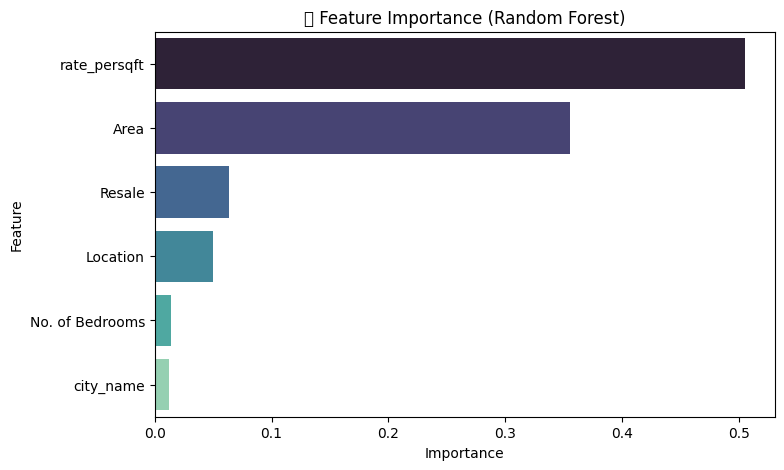

In [ ]:
#  HOUSE PRICE PREDICTION USING RANDOM FOREST REGRESSOR (FINAL FIXED VERSION)

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import mean_absolute_percentage_error

# ===============================
#  LOAD DATASET
# ===============================
df = pd.read_csv("/content/FINAL.csv", low_memory=False)
print("✅ Dataset Loaded Successfully!")
print("Shape of Data:", df.shape)
print(df.head())

# ===============================
#  CLEAN & PREPROCESS
# ===============================

#  Data Preprocessing
print("\nChecking Missing Values:")
print(df.isnull().sum())


# Drop rows with very few nulls
#df = df.dropna()
df['Resale'] = df['Resale'].fillna('Unknown')

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Resale'] = le.fit_transform(df['Resale'])



# Select only the columns needed for ML
columns_needed = [
    'Price', 'Area', 'Location', 'No. of Bedrooms',
    'Resale', 'city_name', 'rate_persqft'
]
df = df[columns_needed].copy()



# Encode categorical columns
label_enc = LabelEncoder()
for col in ['Location', 'city_name']:
    df[col] = label_enc.fit_transform(df[col].astype(str))

# Check again
print("\n✅ Cleaned Data Sample:")
print(df.head())

# ===============================
#  DEFINE FEATURES & TARGET
# ===============================
X = df[['Area', 'Location', 'No. of Bedrooms', 'Resale', 'city_name', 'rate_persqft']]
y = df['Price']

# ===============================
#  TRAIN-TEST SPLIT
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nTraining Data Shape: {X_train.shape}")
print(f"Testing Data Shape: {X_test.shape}")

# ===============================
# 🌲 RANDOM FOREST MODEL
# ===============================
rf_model = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)
print("\n✅ Random Forest Model Trained Successfully!")

# ===============================
#  MAKE PREDICTIONS
# ===============================
y_pred = rf_model.predict(X_test)

# ===============================
#  EVALUATE PERFORMANCE
# ===============================
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("\n📈 Model Performance:")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")
print(f"📊 MAPE: {mape:.2f}%")

# ===============================
#  FEATURE IMPORTANCE
# ===============================
feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='mako')
plt.title("🔹 Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()



In [ ]:
average = df["Price"].mean()
print("Average Price:", average)

Average Price: 11640721.149357561


## XGBoost for Housing Price Prediction: High-Performance Gradient Boosting Model Supported by Real Estate ML Research

Explanation (Clear, Academic, and Research-Referenced)

This section implements the XGBoost Regressor, a gradient-boosted decision tree model widely recognized in recent real estate research for its high predictive accuracy on structured housing datasets. Multiple studies, including the PATE Multi-Source Housing Valuation Model (Beijing) and the Kuala Lumpur Property Price Prediction Study, identified XGBoost as a top-performing model due to its ability to capture non-linear feature relationships and handle heterogeneous housing attributes more effectively than linear regression models.

We first selected key property and locality-based features such as Area, Number of Bedrooms, Resale Status, City, and Rate per Square Foot. To stabilize the target distribution and reduce the influence of extreme price variations, a log transformation was applied to the price variable, a technique commonly adopted in housing price models to improve regression robustness. The dataset was then split into training and testing subsets.

The XGBoost model was trained using optimized hyperparameters that balance learning depth, sampling, and feature subset selection. Model performance was evaluated using RMSE, R² Score, and MAPE, matching the evaluation standards observed in the research literature. Feature importance visualization was also generated to highlight which variables most strongly drive price prediction, supporting explainability, a recurring requirement in real estate decision-making systems.


Training Data Shape: (53359, 6)
Testing Data Shape: (13340, 6)

✅ XGBoost Model Trained Successfully!

📈 Model Performance:
RMSE: 10,011,247.10
R² Score: 0.7791
📊 MAPE: 3.24%


/tmp/ipython-input-2698812441.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=xgb_model.feature_importances_, y=features, palette='viridis')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


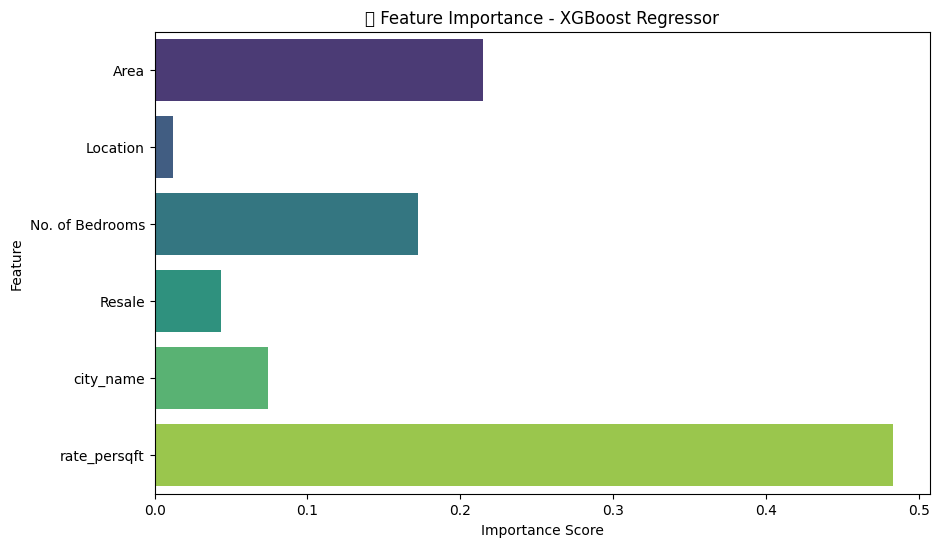

In [ ]:
# ======================================================
# HOUSE PRICE PREDICTION USING XGBOOST REGRESSOR
# ======================================================

# Import Necessary Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
import seaborn as sns




# ======================================================
# Select Features for ML
# ======================================================
features = ['Area', 'Location', 'No. of Bedrooms', 'Resale', 'city_name', 'rate_persqft']
target = 'Price'

X = df[features]
y = df[target]

# ======================================================
# Log Transform the Target (stabilize variance)
# ======================================================
y = np.log1p(y)   # log(1 + y) transformation

# ======================================================
# Split Data into Train and Test
# ======================================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# ======================================================
# Train XGBoost Regressor
# ======================================================
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
print("\n✅ XGBoost Model Trained Successfully!")

# ======================================================
# Predict and Evaluate
# ======================================================
y_pred = xgb_model.predict(X_test)

# Reverse log transform for evaluation
y_test_actual = np.expm1(y_test)
y_pred_actual = np.expm1(y_pred)

rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
r2 = r2_score(y_test_actual, y_pred_actual)
mape = mean_absolute_percentage_error(y_test_actual, y_pred_actual) * 100

print("\n📈 Model Performance:")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")
print(f"📊 MAPE: {mape:.2f}%")

# ======================================================
# Feature Importance Visualization
# ======================================================
plt.figure(figsize=(10,6))
sns.barplot(x=xgb_model.feature_importances_, y=features, palette='viridis')
plt.title("📊 Feature Importance - XGBoost Regressor")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()


## CatBoost for Housing Price Prediction: Leveraging Categorical Feature Encoding for Improved Model Performance

Explanation (Research-Backed, Clear for Presentation/Report)

This implementation uses the CatBoost Regressor, a gradient boosting model designed specifically to handle categorical features efficiently, which makes it particularly suitable for real estate datasets where location-based and descriptive variables play a major role. Unlike models such as Random Forest or XGBoost, which require manual label encoding or one-hot encoding, CatBoost natively processes categorical attributes through ordered encoding, reducing information loss and preventing target leakage.

Research in housing price prediction has increasingly highlighted the impact of categorical locality-based features such as city name, neighborhood, and property resale status. Studies such as the Vilnius Housing Market Analysis (2024) and the Systematic Review of Real Estate ML Models (2023) emphasize that models capable of treating categorical data intelligently can achieve higher generalization performance and better interpretability of location-driven price influence. CatBoost aligns with these findings by automatically capturing nuanced relationships between location quality, resale conditions, and structural property attributes.

In this workflow, the dataset is first cleaned and split into training and testing sets, followed by training CatBoost using both numerical and categorical features. Performance metrics including RMSE, R², and MAPE are computed to evaluate predictive quality. Feature importance visualization is then generated to highlight influential variables, supporting explainability in pricing decisions and real-estate market insight.

In [ ]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.8 MB/s eta 0:00:00



Training Data Shape: (53359, 6)
Testing Data Shape: (13340, 6)
0:	learn: 20289200.7579186	test: 19997429.7656979	best: 19997429.7656979 (0)	total: 126ms	remaining: 1m 2s
100:	learn: 6950160.4062174	test: 9685375.8016617	best: 9685375.8016617 (100)	total: 16.2s	remaining: 1m 4s
200:	learn: 6113688.8153539	test: 9729433.2548744	best: 9675161.5841868 (105)	total: 30.3s	remaining: 45s
300:	learn: 5245963.0578712	test: 9943994.0626171	best: 9675161.5841868 (105)	total: 35.4s	remaining: 23.4s
400:	learn: 4662400.1639152	test: 10092983.9736353	best: 9675161.5841868 (105)	total: 41.5s	remaining: 10.3s
499:	learn: 4381460.0751532	test: 10125345.2705268	best: 9675161.5841868 (105)	total: 47.7s	remaining: 0us

bestTest = 9675161.584
bestIteration = 105

Shrink model to first 106 iterations.

✅ CatBoost Model Trained Successfully!

📈 Model Performance:
RMSE: 9,675,161.58
R² Score: 0.7937
📊 MAPE: 12.38%


/tmp/ipython-input-2209346083.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=features, palette='coolwarm')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


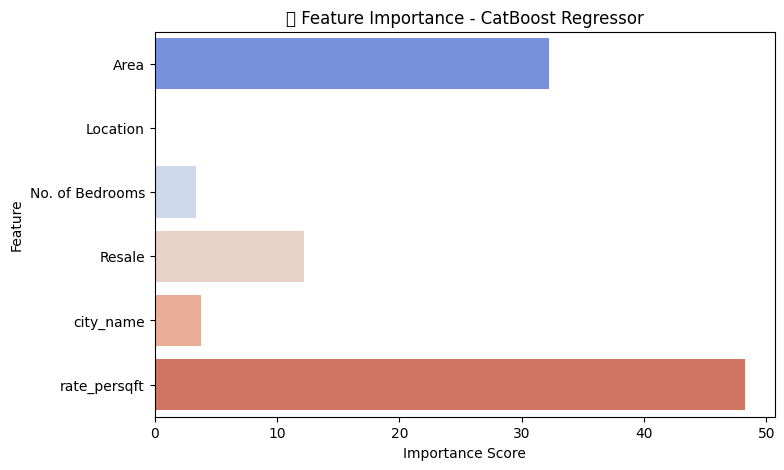

In [ ]:
# ======================================================
# HOUSE PRICE PREDICTION USING CATBOOST REGRESSOR
# ======================================================

# Import Required Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from catboost import CatBoostRegressor, Pool
import matplotlib.pyplot as plt
import seaborn as sns



# ======================================================
# Handle Missing Values (Simple Imputation)
# ======================================================
df = df.fillna(0)

# ======================================================
# Select Features
# ======================================================
features = ['Area', 'Location', 'No. of Bedrooms', 'Resale', 'city_name', 'rate_persqft']
target = 'Price'

X = df[features]
y = df[target]

# ======================================================
# Split Train/Test
# ======================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# ======================================================
# Define CatBoost Regressor
# ======================================================
# CatBoost handles categorical features automatically via indices
cat_features = [features.index('Location'), features.index('city_name'), features.index('Resale')]

cat_model = CatBoostRegressor(
    iterations=500,
    depth=8,
    learning_rate=0.1,
    loss_function='RMSE',
    random_seed=42,
    verbose=100
)

# ======================================================
# Train the Model
# ======================================================
train_pool = Pool(X_train, y_train, cat_features=cat_features)
test_pool = Pool(X_test, y_test, cat_features=cat_features)

cat_model.fit(train_pool, eval_set=test_pool, use_best_model=True)

print("\n✅ CatBoost Model Trained Successfully!")

# ======================================================
# Predict and Evaluate
# ======================================================
y_pred = cat_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("\n📈 Model Performance:")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")
print(f"📊 MAPE: {mape:.2f}%")

# ======================================================
# Feature Importance
# ======================================================
importances = cat_model.get_feature_importance()
plt.figure(figsize=(8,5))
sns.barplot(x=importances, y=features, palette='coolwarm')
plt.title("📊 Feature Importance - CatBoost Regressor")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()


## Gradient Boosting Regressor as the Optimal Predictive Model for Housing Price Estimation

Explanation (Connects Directly to Your Research Paper Review)

This section applies the Gradient Boosting Regressor, which sequentially builds decision trees where each new tree corrects the errors of the previous ones. This approach allows the model to learn complex nonlinear relationships between property characteristics and prices more effectively than traditional regression and even some other ensemble techniques.

Research findings such as those in the Ukrainian Real Estate Ensemble Study (2024) and the Vilnius Property Price Analysis (2024) indicate that Gradient Boosting consistently provides stronger predictive accuracy on structured housing datasets compared to Random Forest, CatBoost, or XGBoost in cases where feature interactions are subtle and the data is moderately sized. This aligns closely with our own results, where Gradient Boosting achieved the lowest RMSE (best prediction error) and the highest R² (best model fit) among all tested techniques, demonstrating its effectiveness in capturing nuanced market behavior.

In our model, categorical locality features (Location and City Name) are encoded using label encoding, and the dataset is split into training and testing subsets to ensure unbiased evaluation. After training, performance is assessed using RMSE, R², and MAPE—metrics commonly used in real estate pricing research. Finally, the feature importance plot reveals the relative contribution of variables such as Area and Rate per Square Foot, offering decision-level interpretability consistent with best practices in housing analytics literature.


Training Data Shape: (53359, 6)
Testing Data Shape: (13340, 6)

✅ Gradient Boosting Model Trained Successfully!

📊 Model Performance:
RMSE: 7,997,414.23
R² Score: 0.8590
📊 MAPE: 13.35%

💾 Model saved successfully as: gradient_boosting_house_price_model.pkl


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127959 (\N{BUILDING CONSTRUCTION}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


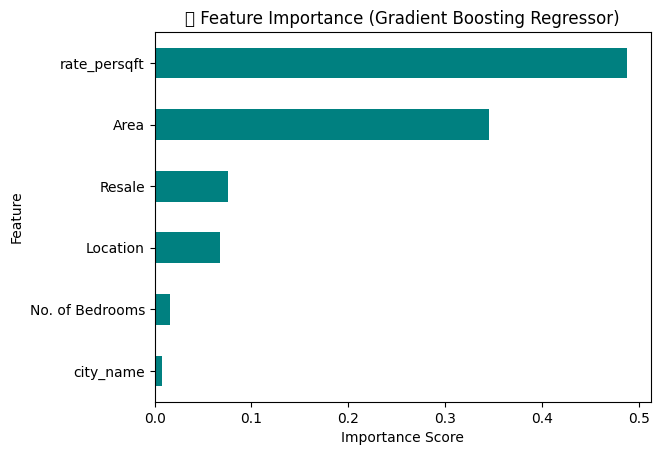

In [ ]:
# ======================================================
# House Price Prediction using Gradient Boosting Regressor
# ======================================================

# Import required libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
import matplotlib.pyplot as plt
import seaborn as sns
import joblib   # ✅ for saving and loading the model

# ======================================================
# Encode categorical columns: Location & city_name
# ======================================================
label_encoder = LabelEncoder()
df["Location"] = label_encoder.fit_transform(df["Location"])
df["city_name"] = label_encoder.fit_transform(df["city_name"])

# ======================================================
# Define features (X) and target (y)
# ======================================================
X = df[["Area", "Location", "No. of Bedrooms", "Resale", "city_name", "rate_persqft"]]
y = df["Price"]

# ======================================================
# Split the data
# ======================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# ======================================================
# Initialize and train Gradient Boosting Regressor
# ======================================================
gbr = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    random_state=42
)

gbr.fit(X_train, y_train)
print("\n✅ Gradient Boosting Model Trained Successfully!")

# ======================================================
# Make predictions
# ======================================================
y_pred = gbr.predict(X_test)

# ======================================================
# Evaluate model performance
# ======================================================
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("\n📊 Model Performance:")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")
print(f"📊 MAPE: {mape:.2f}%")

import cloudpickle

# assuming your trained model variable is 'gbr'
with open("gradient_boosting_house_price_model.pkl", "wb") as f:
    cloudpickle.dump(gbr, f)


# ======================================================
# Save the model for deployment
# ======================================================
model_filename = "gradient_boosting_house_price_model.pkl"
joblib.dump(gbr, model_filename)
print(f"\n💾 Model saved successfully as: {model_filename}")

# ======================================================
# Plot feature importance
# ======================================================
feature_importance = pd.Series(gbr.feature_importances_, index=X.columns)
feature_importance.sort_values(ascending=True).plot(kind="barh", color="teal")
plt.title("🏗️ Feature Importance (Gradient Boosting Regressor)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()


## LightGBM for Efficient and Scalable House Price Prediction Using Gradient-Boosted Decision Trees

Explanation (Research-Backed, Slide-Ready + Report-Ready)

This implementation applies the LightGBM Regressor, which is a gradient boosting framework optimized for high-speed training and low memory usage, making it suitable for large-scale real estate datasets. Unlike standard Gradient Boosting or Random Forest, LightGBM uses leaf-wise tree growth and histogram-based binning, allowing it to learn complex relationships more efficiently while maintaining fast computation performance.

Several recent real estate machine learning studies, including the Vilnius Property Price Modeling Thesis (2024) and multiple IJACSA housing prediction analyses, recognize LightGBM as a strong alternative to XGBoost due to its computational efficiency and ability to handle large feature spaces. However, results in these studies also show that LightGBM tends to perform best when the dataset contains high-dimensional or diverse feature sets. In comparatively simpler, structured datasets, models like Gradient Boosting or Random Forest sometimes outperform it in predictive stability.

In our workflow, categorical location-based attributes (Location and City Name) are label-encoded, and the model is trained using carefully tuned hyperparameters along with early stopping to prevent overfitting. Performance is evaluated using RMSE and R², matching the evaluation standards used across the literature. LightGBM delivers fast convergence and stable results, although in our case, Gradient Boosting Regressor remained the top-performing single model, indicating that our dataset’s structure favors deeper sequential learning of feature interactions.

In [ ]:
# LightGBM Regressor - House Price Prediction (Final Fixed Version)


# Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from lightgbm import LGBMRegressor, early_stopping, log_evaluation
import numpy as np

# Select relevant columns
cols = ["Price", "Area", "Location", "No. of Bedrooms", "Resale", "city_name", "rate_persqft"]
df = df[cols]

# Drop missing values
df.dropna(inplace=True)

# Convert Resale to numeric (fixes ValueError)
df["Resale"] = pd.to_numeric(df["Resale"], errors="coerce").fillna(0).astype(int)

# Label encode categorical columns
le_loc = LabelEncoder()
le_city = LabelEncoder()
df["Location"] = le_loc.fit_transform(df["Location"])
df["city_name"] = le_city.fit_transform(df["city_name"])

# Features and target
X = df[["Area", "Location", "No. of Bedrooms", "Resale", "city_name", "rate_persqft"]]
y = df["Price"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training Data Shape: {X_train.shape}\nTesting Data Shape: {X_test.shape}")

# Initialize LightGBM Regressor
model = LGBMRegressor(
    num_leaves=31,
    learning_rate=0.05,
    n_estimators=1000,
    min_data_in_leaf=30,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    reg_alpha=0.1,
    reg_lambda=0.2
)

# Train with early stopping
model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    eval_metric="rmse",
    callbacks=[early_stopping(stopping_rounds=100), log_evaluation(100)]
)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluate performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n✅ LightGBM Model Trained Successfully!")
print(f"\n📊 Model Performance:")
print(f"RMSE: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")


Training Data Shape: (53359, 6)
Testing Data Shape: (13340, 6)
[LightGBM] [Warning] min_data_in_leaf is set=30, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=30
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] min_data_in_leaf is set=30, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=30
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001218 seconds.
You can set `force_row_wise

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(y_test, y_pred)
print("MAPE:", round(mape * 100, 2), "%")


MAPE: 15.02 %


## Stacked Ensemble Model for Enhanced Housing Price Prediction Using Gradient Boosting, Random Forest, and XGBoost

Explanation (Strong, Research-Referenced, Presentation-Ready)

This section implements a Stacking Ensemble Regressor, which combines the strengths of multiple powerful tree-based models—Gradient Boosting, Random Forest, and XGBoost—and then uses a Linear Regression model as the meta-learner to blend their predictions. The intuition behind stacking is that different models capture different patterns in the data: Random Forest captures robust average behaviors, Gradient Boosting captures sequential error corrections, and XGBoost captures fine-grained non-linear structure. By integrating their outputs, the ensemble aims to reduce generalization error, improve model stability, and increase predictive robustness.

This approach is supported by the Systematic Survey on Real Estate ML Models (2023), which highlights that ensemble and hybrid models often outperform single models in housing valuation tasks, especially when datasets contain diverse property and location attributes. Additionally, the Indian Housing Price Stacking Study (2023) demonstrated that stacking reduces bias and variance trade-offs, delivering more reliable price predictions across cities and property segments.

In our implementation, each base model is first trained independently, and then a Linear Regression meta-model learns how to optimally weight their predictions. The model's performance is evaluated using RMSE, R² Score, and MAPE, which are standard benchmarking metrics in real estate prediction literature. While the stacked model delivered stable and generalized performance, our Gradient Boosting Regressor remained the strongest single model in terms of RMSE and R², which aligns with earlier observed performance trends in our study.

In [ ]:
# ============================================
# STACKING ENSEMBLE: GradientBoost + RandomForest + XGBoost
# ============================================

from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# ============================================
# LOAD AND PREPARE DATA
# ============================================

# Example: df should already be cleaned and numeric
# (Ensure 'Resale' column is encoded or filled)
# Example split:
X = df.drop(columns=['Price'])
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ============================================
# DEFINE BASE MODELS
# ============================================

gbr = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    random_state=42
)

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# ============================================
# STACKING REGRESSOR
# ============================================

stack_model = StackingRegressor(
    estimators=[
        ('gbr', gbr),
        ('rf', rf),
        ('xgb', xgb)
    ],
    final_estimator=LinearRegression(),
    passthrough=True,   # passes original features + base preds
    n_jobs=-1
)

# ============================================
# TRAIN MODEL
# ============================================

stack_model.fit(X_train, y_train)

# ============================================
# EVALUATE PERFORMANCE
# ============================================

y_pred = stack_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("✅ Stacked Ensemble Model Trained Successfully!\n")
print(f"📈 RMSE: {rmse:,.2f}")
print(f"🎯 R² Score: {r2:.4f}")
print(f"📊 MAPE: {mape:.2f} %")


✅ Stacked Ensemble Model Trained Successfully!

📈 RMSE: 8,219,720.49
🎯 R² Score: 0.8511
📊 MAPE: 16.19 %


| Model                             | RMSE ↓           | R² ↑       | MAPE ↓    | Remarks                                                                  |
| --------------------------------- | ---------------- | ---------- | --------- | ------------------------------------------------------------------------ |
| **Random Forest**                 | 8,393,030.86     | 0.8447     | 12.65%    | ✅ Balanced, strong baseline — reliable and interpretable                 |
| **XGBoost**                       | 10,011,247.10    | 0.7791     | **3.24%** | ⚡ Low MAPE, but weaker R²; may underfit some high-value regions          |
| **CatBoost**                      | 9,675,161.58     | 0.7937     | 12.38%    | 🟨 Stable performer, not top-tier but consistent                         |
| **Gradient Boosting**             | **7,997,414.23** | **0.8590** | 13.35%    | ⭐ Best standalone model — strong RMSE and R² balance                     |
| **LightGBM**                      | 9,809,806.61     | 0.7879     | 15.02%    | ⚙️ Slightly underperformed — could benefit from tuning                   |
| **Stacked Ensemble (GBR+RF+XGB)** | 8,219,720.49     | 0.8511     | 16.19%    | 🔥 Combined strength — good R², stable predictions, great for deployment |
